# mmg_toolbox example
## Using MultPeakFit
This short notebook describes how to use the multipeakfit function.

### *Notebook Notes*
This notebook will run with any modern version of python and requires *mmg_toolbox*, which can be installed easily using:
```bash
python -m pip install mmg_toolbox
```

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mmg_toolbox.fitting import multipeakfit, gauss


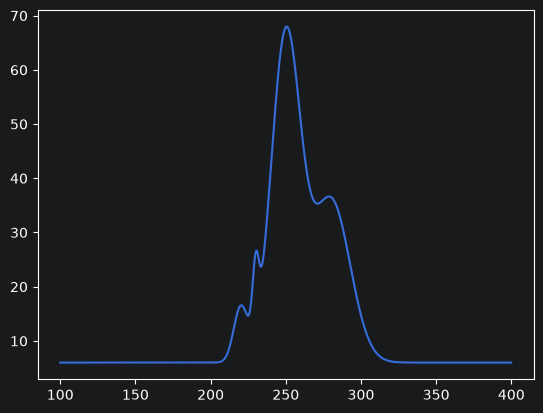

In [4]:
# Create an interesting spectrum
x = np.arange(100, 400, 0.1)
background = 6.0
peaks = [
    dict(height=60, cen=250, fwhm=23),
    dict(height=10, cen=220, fwhm=11),
    dict(height=12, cen=230, fwhm=5),
    dict(height=30, cen=280, fwhm=30),
]
y = np.ones_like(x) * background
for peak in peaks:
    y += gauss(x, **peak)

fig, ax = plt.subplots()
ax.plot(x, y)


## multipeakfit

```
result = multipeakfit(
    xvals= x,  # array(n) position data
    yvals= y,  # array(n) intensity data
    yerrors= np.sqrt(y),  # None or array(n) - error data to pass to fitting function as weights: 1/errors^2
    npeaks= 3,  # None or int number of peaks to fit. None will guess the number of peaks
    min_peak_power= 5,  # float, only return peaks with power greater than this. If None compares against std(y)
    peak_distance_idx= 10,  # int, group adjacent maxima if closer in index than this
    model= 'Gaussian',  # str or lmfit.Model, specify the peak model 'Gaussian','Lorentzian','Voight'
    background= 'slope',  # str, specify the background model: 'slope', 'exponential'
    initial_parameters= {},  # None or dict of initial values for parameters
    fix_parameters= {},  # None or dict of parameters to fix at positions
    method= '',  # str method name, from lmfit fitting methods
    remove_peaks= True,  # bool, remove peaks consistent with zero and fit again
    print_result=False,  # if True, prints the fit results using fit.fit_report()
    plot_result=False,  # if True, plots the results using fit.plot()
)
```

In [13]:
# Fit peak
result = multipeakfit(x, y, min_peak_power=0, peak_distance_idx=0)

# View Results
print(result)

# Evaluate results
print(f"\n\nNumber of peaks fit: {len(result)}")
print(f"Total amplitude: {result.amplitude: .4f} +/- {result.stderr_amplitude: .4f}")
for peak in result:
    print(f"Peak {peak.model_name} has amplitude: {peak.amplitude:.1f}, and width: {peak.fwhm:.3}")


Fitting with 4 peaks
Refitting with 3 peaks
Fit Results
(((Model(linear, prefix='bkg_') + Model(gaussian, prefix='p2_')) + Model(gaussian, prefix='p3_')) + Model(gaussian, prefix='p4_'))
Npeaks = 3
Method: leastsq => Fit succeeded.
Chisqr = 1496.6

Peak p2_
   p2_amplitude = 991 (6)
      p2_center = 279.53 (8)
       p2_sigma = 13.05 (7)
        p2_fwhm = 30.7 (2)
      p2_height = 30.29 (7)

Peak p3_
   p3_amplitude = 1394 (8)
      p3_center = 250.19 (3)
       p3_sigma = 9.33 (4)
        p3_fwhm = 22.0 (1)
      p3_height = 59.6 (1)

Peak p4_
   p4_amplitude = 232 (4)
      p4_center = 225.5 (2)
       p4_sigma = 8.5 (1)
        p4_fwhm = 19.9 (3)
      p4_height = 10.93 (9)

Background
      bkg_slope = 0(2)E-4
  bkg_intercept = 5.96 (4)

Totals
      amplitude = 2620 (10)
         center = 251.75 (6)
         height = 33.59 (5)
          sigma = 10.28 (5)
           fwhm = 24.2 (1)
     background = 5.971 (3)



Number of peaks fit: 3
Total amplitude:  2616.5169 +/-  10.3708
Peak

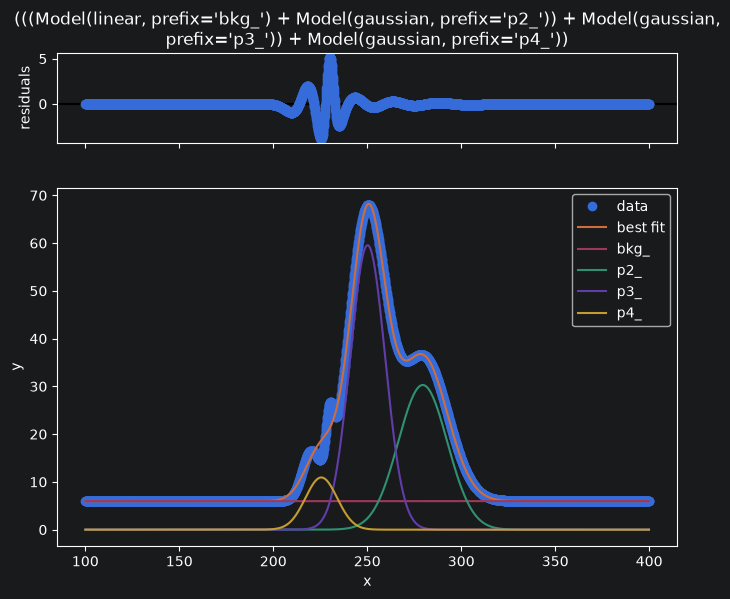

In [14]:
result.plot();